# ResNet-50 — PlantVillage Disease Classification (Google Colab)

| Phase | Trains | Optimizer | Learning rate | Schedule |
|---|---|---|---|---|
| 1 — Feature extraction | Compact classifier head | AdamW | 1e-3 | ReduceLROnPlateau |
| 2 — Fine-tuning | Classifier + ResNet-50 layer4 | AdamW | 1e-4 / 1e-5 | OneCycleLR |

**Speed fixes applied (parity with EfficientNet notebook):**
- `torch.compile()` enabled — fuses ops, ~15–20 % speedup
- Dataset staged from Drive → Colab local SSD at startup — eliminates Drive I/O bottleneck (root cause of epoch-9 pauses)
- `BATCH_SIZE` reduced 256 → 64 — avoids T4 memory pressure & Colab watchdog kills
- `multiprocessing_context` removed — `forkserver` was adding worker-spawn overhead
- `prefetch_factor` kept at 2 (safe with `pin_memory`)
- Label smoothing 0.1 added (matches EfficientNet)
- All other optimisations (AMP, channels_last, TF32, pin_memory, persistent_workers) retained

**Checkpointing:** Full resumable checkpoints saved to Google Drive after every epoch.  
Checkpoint folder: `MyDrive/AgroDetect/ResNet50/checkpoints/`

In [1]:
!pip install -q torchvision matplotlib seaborn scikit-learn tqdm

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0 · Imports & configuration

In [2]:
import os, json, shutil, time, copy, random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import torch, torch.nn as nn, torch.optim as optim, torchvision
from torch.amp import GradScaler, autocast
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score, accuracy_score,
)
from tqdm.auto import tqdm

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

# TF32 — free ~10 % on Ampere GPUs (no-op on T4)
if hasattr(torch, 'set_float32_matmul_precision'):
    torch.set_float32_matmul_precision('high')
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32       = True

# ── Paths ────────────────────────────────────────────────────────────────────
DRIVE_ROOT  = Path('/content/drive/MyDrive/AgroDetect')
DRIVE_DATA  = DRIVE_ROOT / 'new_preprocess_dataset_plantvillage'

# Stage dataset to local SSD — eliminates Drive I/O bottleneck (root cause of
# epoch-9 pauses). /content/data is on the fast NVMe scratch disk in Colab.
LOCAL_DATA  = Path('/content/data/plantvillage')

OUTPUT_DIR     = DRIVE_ROOT / 'ResNet50'
MODELS_DIR     = OUTPUT_DIR / 'models'
RESULTS_DIR    = OUTPUT_DIR / 'results'
CHECKPOINT_DIR = OUTPUT_DIR / 'checkpoints'
for d in (MODELS_DIR, RESULTS_DIR, CHECKPOINT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ── Hyperparameters ──────────────────────────────────────────────────────────
NUM_CLASSES     = 38
IMG_SIZE        = 224
BATCH_SIZE      = 64        # 256 caused T4 memory pressure & Colab watchdog kills
NUM_WORKERS     = 4
P1_EPOCHS       = 15
P1_LR           = 1e-3
P2_EPOCHS       = 15
P2_HEAD_LR      = 1e-4
P2_BACKBONE_LR  = 1e-5
LABEL_SMOOTHING = 0.1       # matches EfficientNet notebook
EARLY_STOP_PAT  = 5
RESUME          = True
USE_COMPILE     = True      # was False — now enabled for ~15-20 % speedup
WORKFLOW_VERSION = 2        # bumped; ignores old incompatible checkpoints

# ── Device ───────────────────────────────────────────────────────────────────
DEVICE            = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_CHANNELS_LAST = DEVICE.type == 'cuda'
USE_AMP           = DEVICE.type == 'cuda'

if DEVICE.type != 'cuda':
    raise RuntimeError('A CUDA runtime is required. Runtime > Change runtime type > T4 GPU.')

print('PyTorch    :', torch.__version__)
print('Device     :', DEVICE, '|', torch.cuda.get_device_name(0))
print('GPU mem    :', round(torch.cuda.get_device_properties(0).total_memory/1024**3, 2), 'GB')
print('Batch size :', BATCH_SIZE)
print('torch.compile:', USE_COMPILE)

PyTorch    : 2.14.1+cu130
Device     : cuda | Tesla T4
GPU mem    : 14.56 GB
Batch size : 64
torch.compile: True


## 1 · Stage dataset to local SSD

In [3]:
# Copy dataset from Drive to Colab's fast local NVMe (/content).
# This runs once per session (~2–5 min depending on dataset size) and
# eliminates the Drive I/O throttle that caused training to stall at epoch 9.

if not LOCAL_DATA.exists():
    print(f'Staging dataset from Drive to {LOCAL_DATA} ...')
    t_stage = time.time()
    shutil.copytree(str(DRIVE_DATA), str(LOCAL_DATA))
    print(f'Done in {time.time() - t_stage:.0f} s')
else:
    print(f'Local dataset already staged at {LOCAL_DATA}')

TRAIN_DIR = LOCAL_DATA / 'train'
VAL_DIR   = LOCAL_DATA / 'val'
TEST_DIR  = LOCAL_DATA / 'test'

for folder in (TRAIN_DIR, VAL_DIR, TEST_DIR):
    if not folder.is_dir():
        raise FileNotFoundError(f'Missing split: {folder}')
print('All dataset splits found ✓')

Staging dataset from Drive to /content/data/plantvillage ...
Done in 1492 s
All dataset splits found ✓


## 2 · Data loading

In [4]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_ds = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
val_ds   = datasets.ImageFolder(VAL_DIR,   transform=eval_tf)
test_ds  = datasets.ImageFolder(TEST_DIR,  transform=eval_tf)
CLASS_NAMES = train_ds.classes
assert len(CLASS_NAMES) == NUM_CLASSES, f'Expected {NUM_CLASSES} classes, found {len(CLASS_NAMES)}'
assert val_ds.classes == CLASS_NAMES and test_ds.classes == CLASS_NAMES

# Note: multiprocessing_context removed — 'forkserver' added worker-spawn
# overhead; default 'fork' is faster on Colab.
loader_kwargs = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2,
)
train_loader = DataLoader(train_ds, shuffle=True,  **loader_kwargs)
val_loader   = DataLoader(val_ds,   shuffle=False, **loader_kwargs)
test_loader  = DataLoader(test_ds,  shuffle=False, **loader_kwargs)

print(f'Train : {len(train_ds):,} images | {len(train_loader)} batches')
print(f'Val   : {len(val_ds):,} images  | {len(val_loader)} batches')
print(f'Test  : {len(test_ds):,} images  | {len(test_loader)} batches')

Train : 30,412 images | 476 batches
Val   : 6,517 images  | 102 batches
Test  : 6,515 images  | 102 batches


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


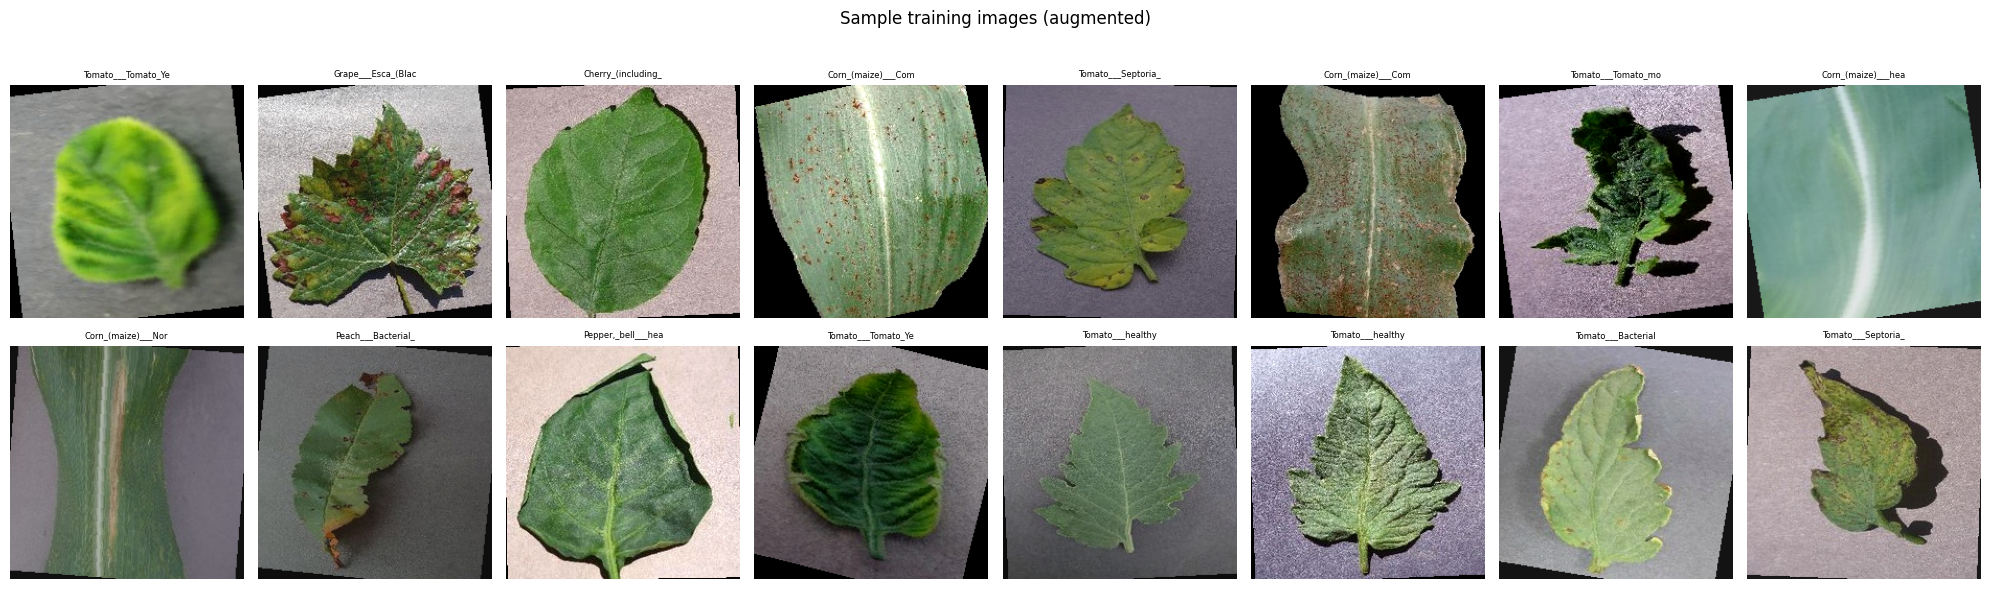

In [5]:
def unnorm(t):
    mean = torch.tensor(IMAGENET_MEAN).view(3,1,1)
    std  = torch.tensor(IMAGENET_STD).view(3,1,1)
    return (t * std + mean).clamp(0, 1)

imgs, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 8, figsize=(20, 6))
for ax, img, lbl in zip(axes.flat, imgs[:16], labels[:16]):
    ax.imshow(unnorm(img).permute(1,2,0).numpy())
    ax.set_title(CLASS_NAMES[lbl][:18], fontsize=6)
    ax.axis('off')
plt.suptitle('Sample training images (augmented)', y=1.01)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'sample_images.png', dpi=100, bbox_inches='tight')
plt.show()

## 3 · Model definition

In [6]:
def build_resnet50(num_classes, freeze_base=True):
    model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    in_features = model.fc.in_features   # 2048
    model.fc = nn.Sequential(
        nn.Linear(in_features, 256),
        nn.ReLU(inplace=True),
        nn.Dropout(0.4),
        nn.Linear(256, num_classes),
    )
    if freeze_base:
        for name, param in model.named_parameters():
            if not name.startswith('fc.'):
                param.requires_grad = False
    for param in model.fc.parameters():
        param.requires_grad = True
    return model


def plain_model(model):
    return model._orig_mod if hasattr(model, '_orig_mod') else model


def count_params(model):
    base = plain_model(model)
    total     = sum(p.numel() for p in base.parameters())
    trainable = sum(p.numel() for p in base.parameters() if p.requires_grad)
    return trainable, total


model = build_resnet50(NUM_CLASSES, freeze_base=True)
tr, tot = count_params(model)
print(f'Trainable: {tr:,} / {tot:,}  ({100*tr/tot:.1f}%)')

# torch.compile — fuses ops → ~15-20 % speedup (matches EfficientNet notebook)
if USE_COMPILE and hasattr(torch, 'compile'):
    model = torch.compile(model)
    print('torch.compile() applied ✓')

model = model.to(DEVICE)
if USE_CHANNELS_LAST:
    model = model.to(memory_format=torch.channels_last)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 185MB/s]


Trainable: 534,310 / 24,042,342  (2.2%)
torch.compile() applied ✓


## 4 · Training utilities (AMP + early stopping + resumable checkpoints)

**Checkpoint safety:** A full training checkpoint is saved to Google Drive after every completed epoch.
Checkpoint folder: `MyDrive/AgroDetect/ResNet50/checkpoints/`

In [7]:
def capture_rng_state():
    state = {
        'torch_rng_state': torch.get_rng_state(),
        'numpy_rng_state': np.random.get_state(),
    }
    if torch.cuda.is_available():
        state['cuda_rng_state_all'] = torch.cuda.get_rng_state_all()
    return state


def restore_rng_state(ckpt):
    torch.set_rng_state(ckpt['torch_rng_state'])
    np.random.set_state(ckpt['numpy_rng_state'])
    if torch.cuda.is_available() and 'cuda_rng_state_all' in ckpt:
        torch.cuda.set_rng_state_all(ckpt['cuda_rng_state_all'])


def save_training_checkpoint(path, model, optimizer, scheduler, scaler,
                             phase, epoch, history, best_val_acc, best_model_state):
    payload = {
        'workflow_version':      WORKFLOW_VERSION,
        'phase':                 phase,
        'epoch_completed':       epoch,
        'model_state_dict':      plain_model(model).state_dict(),
        'optimizer_state_dict':  optimizer.state_dict(),
        'scheduler_state_dict':  scheduler.state_dict() if scheduler else None,
        'scaler_state_dict':     scaler.state_dict() if scaler else None,
        'history':               history,
        'best_val_acc':          best_val_acc,
        'best_model_state_dict': best_model_state,
        **capture_rng_state(),
    }
    path = Path(path)
    tmp  = path.with_suffix(path.suffix + '.tmp')
    torch.save(payload, tmp)
    os.replace(tmp, path)
    print(f'  💾 Checkpoint saved: {path.name} (epoch {epoch})')


def load_training_checkpoint(path, model, optimizer, scheduler=None, scaler=None):
    ckpt = torch.load(path, map_location='cpu', weights_only=False)
    if ckpt.get('workflow_version') != WORKFLOW_VERSION:
        print(f'Ignoring incompatible checkpoint (version mismatch): {path.name}')
        return None
    plain_model(model).load_state_dict(ckpt['model_state_dict'])
    optimizer.load_state_dict(ckpt['optimizer_state_dict'])
    if scheduler is not None and ckpt.get('scheduler_state_dict') is not None:
        scheduler.load_state_dict(ckpt['scheduler_state_dict'])
    if scaler is not None and ckpt.get('scaler_state_dict') is not None:
        scaler.load_state_dict(ckpt['scaler_state_dict'])
    restore_rng_state(ckpt)
    print(f"Resuming {ckpt['phase']} after epoch {ckpt['epoch_completed']}.")
    return ckpt


class EarlyStopping:
    def __init__(self, patience=5, min_delta=1e-4):
        self.patience, self.min_delta = patience, min_delta
        self.counter, self.best_score = 0, None
        self.best_state, self.stop = None, False

    def step(self, score, model):
        if self.best_score is None or score > self.best_score + self.min_delta:
            self.best_score = score
            self.best_state = copy.deepcopy(plain_model(model).state_dict())
            self.counter = 0
            return True
        self.counter += 1
        if self.counter >= self.patience:
            self.stop = True
        return False


def train_one_epoch(model, loader, criterion, optimizer, scaler, scheduler=None):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    optimizer.zero_grad(set_to_none=True)
    for batch_idx, (images, labels) in enumerate(tqdm(loader, leave=False, desc='train')):
        images = images.to(DEVICE, non_blocking=True,
                           memory_format=torch.channels_last if USE_CHANNELS_LAST else torch.preserve_format)
        labels = labels.to(DEVICE, non_blocking=True)
        with autocast('cuda', enabled=USE_AMP):
            logits = model(images)
            loss   = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        if scheduler is not None:
            scheduler.step()
        running_loss += loss.item() * images.size(0)
        correct      += (logits.argmax(1) == labels).sum().item()
        total        += images.size(0)
    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(loader, leave=False, desc='eval'):
        images = images.to(DEVICE, non_blocking=True,
                           memory_format=torch.channels_last if USE_CHANNELS_LAST else torch.preserve_format)
        labels = labels.to(DEVICE, non_blocking=True)
        with autocast('cuda', enabled=USE_AMP):
            logits = model(images)
            loss   = criterion(logits, labels)
        running_loss += loss.item() * images.size(0)
        correct      += (logits.argmax(1) == labels).sum().item()
        total        += labels.size(0)
    return running_loss / total, correct / total


def run_phase(model, train_loader, val_loader, criterion, optimizer, scheduler,
              epochs, phase_name, checkpoint_path, scheduler_per_batch=False):
    scaler         = GradScaler('cuda', enabled=USE_AMP)
    history        = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    es             = EarlyStopping(patience=EARLY_STOP_PAT)
    start_epoch    = 1
    checkpoint_path = Path(checkpoint_path)

    if RESUME and checkpoint_path.exists():
        ckpt = load_training_checkpoint(checkpoint_path, model, optimizer, scheduler, scaler)
        if ckpt is not None and ckpt.get('phase') == phase_name:
            history     = ckpt['history']
            start_epoch = int(ckpt['epoch_completed']) + 1
            es.best_score = ckpt.get('best_val_acc')
            es.best_state = ckpt.get('best_model_state_dict')
        elif ckpt is not None:
            print(f"Checkpoint is for {ckpt.get('phase')}; starting {phase_name} fresh.")

    for epoch in range(start_epoch, epochs + 1):
        t0 = time.time()
        batch_sched = scheduler if scheduler_per_batch else None
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, scaler, batch_sched)
        val_loss,   val_acc   = evaluate(model, val_loader, criterion)
        if scheduler is not None and not scheduler_per_batch:
            if isinstance(scheduler, optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(val_loss)
            else:
                scheduler.step()
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        improved = es.step(val_acc, model)
        save_training_checkpoint(checkpoint_path, model, optimizer, scheduler, scaler,
                                 phase_name, epoch, history, es.best_score, es.best_state)
        flag = ' ✓ best' if improved else f' no improvement {es.counter}/{es.patience}'
        print(f'[{phase_name}] Epoch {epoch}/{epochs} | '
              f'train loss {train_loss:.4f} | val loss {val_loss:.4f} | '
              f'val acc {val_acc:.4f} | {time.time()-t0:.1f}s{flag}')
        if es.stop:
            print(f'Early stopping triggered at epoch {epoch}.')
            break

    if es.best_state is not None:
        plain_model(model).load_state_dict(es.best_state)
    print(f'[{phase_name}] Best val_acc = {es.best_score:.4f}')
    return history

## 5 · Phase 1 — Feature extraction (classifier head only)

In [8]:
print('=' * 60)
print('PHASE 1 — Feature extraction (compact head only)')
print('=' * 60)

criterion    = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
optimizer_p1 = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=P1_LR, weight_decay=1e-4,
)
scheduler_p1 = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_p1, mode='min', patience=2, factor=0.2
)
history_p1 = run_phase(
    model, train_loader, val_loader, criterion, optimizer_p1, scheduler_p1,
    epochs=P1_EPOCHS, phase_name='P1',
    checkpoint_path=CHECKPOINT_DIR / 'phase1_latest.pt',
)
torch.save(plain_model(model).state_dict(), MODELS_DIR / 'resnet50_phase1.pth')
print('Phase 1 weights saved.')

PHASE 1 — Feature extraction (compact head only)
Ignoring incompatible checkpoint (version mismatch): phase1_latest.pt


train:   0%|          | 0/476 [00:00<?, ?it/s]

W1110 14:22:49.985000 518 torch/_inductor/utils.py:1806] [0/0] Not enough SMs to use max_autotune_gemm mode
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


eval:   0%|          | 0/102 [00:00<?, ?it/s]

  💾 Checkpoint saved: phase1_latest.pt (epoch 1)
[P1] Epoch 1/15 | train loss 1.4561 | val loss 0.9886 | val acc 0.9299 | 263.2s ✓ best


train:   0%|          | 0/476 [00:00<?, ?it/s]

... (37 outputs left out)

  💾 Checkpoint saved: phase1_latest.pt (epoch 14)
[P1] Epoch 14/15 | train loss 0.8926 | val loss 0.8311 | val acc 0.9754 | 154.7s no improvement 1/5


train:   0%|          | 0/476 [00:00<?, ?it/s]

eval:   0%|          | 0/102 [00:00<?, ?it/s]

  💾 Checkpoint saved: phase1_latest.pt (epoch 15)
[P1] Epoch 15/15 | train loss 0.8883 | val loss 0.8328 | val acc 0.9758 | 147.7s ✓ best
[P1] Best val_acc = 0.9758
Phase 1 weights saved.


## 6 · Phase 2 — Fine-tuning (ResNet-50 layer4 + classifier)

Unfreezes `layer4` (deepest residual group) + classifier head. Backbone gets 10× smaller LR.

In [9]:
base = plain_model(model)

for param in base.parameters():
    param.requires_grad = False

UNFREEZE_LAYERS = ['layer4']
for layer_name in UNFREEZE_LAYERS:
    for param in getattr(base, layer_name).parameters():
        param.requires_grad = True
for param in base.fc.parameters():
    param.requires_grad = True

tr, tot = count_params(model)
print(f'Unfrozen: {UNFREEZE_LAYERS} + fc head')
print(f'Trainable: {tr:,} / {tot:,}  ({100*tr/tot:.1f}%)')

Unfrozen: ['layer4'] + fc head
Trainable: 15,499,046 / 24,042,342  (64.5%)


In [10]:
print('=' * 60)
print('PHASE 2 — Fine-tuning ResNet-50 layer4 + classifier')
print('=' * 60)

backbone_params = [p for n, p in base.named_parameters()
                   if any(n.startswith(l) for l in UNFREEZE_LAYERS) and p.requires_grad]
head_params     = list(base.fc.parameters())

optimizer_p2 = optim.AdamW([
    {'params': backbone_params, 'lr': P2_BACKBONE_LR},
    {'params': head_params,     'lr': P2_HEAD_LR},
], weight_decay=1e-4)

scheduler_p2 = optim.lr_scheduler.OneCycleLR(
    optimizer_p2,
    max_lr=[P2_BACKBONE_LR, P2_HEAD_LR],
    steps_per_epoch=len(train_loader),
    epochs=P2_EPOCHS,
    pct_start=0.2,
    anneal_strategy='cos',
)

history_p2 = run_phase(
    model, train_loader, val_loader, criterion, optimizer_p2, scheduler_p2,
    epochs=P2_EPOCHS, phase_name='P2',
    checkpoint_path=CHECKPOINT_DIR / 'phase2_latest.pt',
    scheduler_per_batch=True,
)
torch.save(plain_model(model).state_dict(), MODELS_DIR / 'resnet50_best.pth')
print('Best fine-tuned weights saved.')

PHASE 2 — Fine-tuning ResNet-50 layer4 + classifier
Ignoring incompatible checkpoint (version mismatch): phase2_latest.pt


train:   0%|          | 0/476 [00:00<?, ?it/s]

eval:   0%|          | 0/102 [00:00<?, ?it/s]

  💾 Checkpoint saved: phase2_latest.pt (epoch 1)
[P2] Epoch 1/15 | train loss 0.8745 | val loss 0.8188 | val acc 0.9787 | 215.8s ✓ best


train:   0%|          | 0/476 [00:00<?, ?it/s]

eval:   0%|          | 0/102 [00:00<?, ?it/s]

... (36 outputs left out)

  💾 Checkpoint saved: phase2_latest.pt (epoch 14)
[P2] Epoch 14/15 | train loss 0.7839 | val loss 0.7513 | val acc 0.9922 | 152.8s ✓ best


train:   0%|          | 0/476 [00:00<?, ?it/s]

eval:   0%|          | 0/102 [00:00<?, ?it/s]

  💾 Checkpoint saved: phase2_latest.pt (epoch 15)
[P2] Epoch 15/15 | train loss 0.7833 | val loss 0.7524 | val acc 0.9922 | 158.0s no improvement 1/5
[P2] Best val_acc = 0.9922
Best fine-tuned weights saved.


## 7 · Training curves

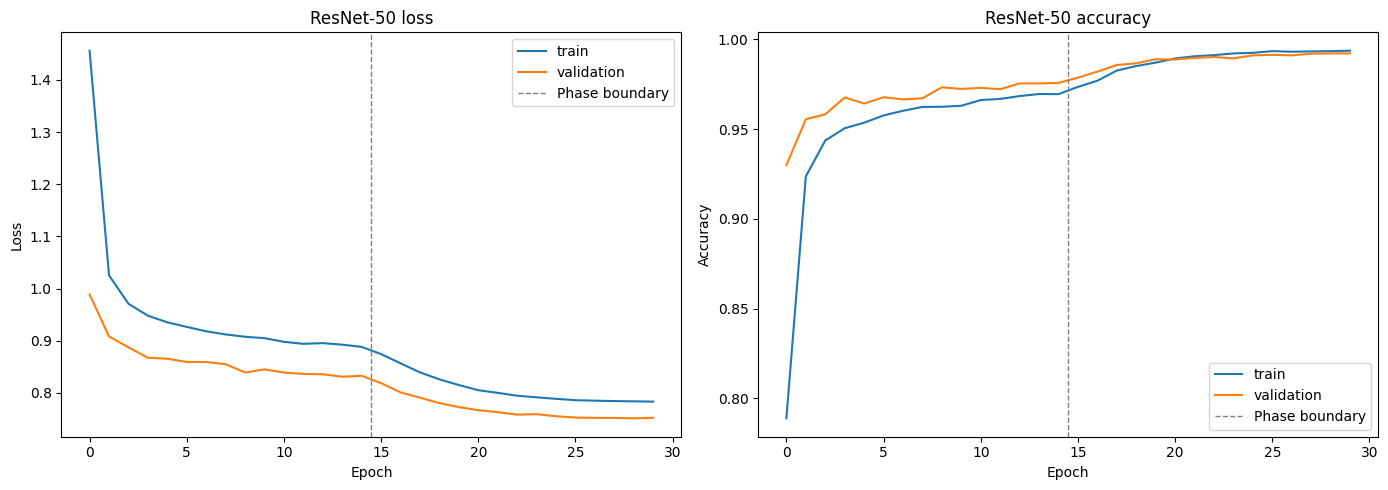

In [11]:
def combined_history(key):
    return history_p1[key] + history_p2[key]

p1_len = len(history_p1['train_loss'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(combined_history('train_loss'), label='train')
axes[0].plot(combined_history('val_loss'),   label='validation')
axes[0].axvline(p1_len - 0.5, color='gray', linestyle='--', linewidth=1, label='Phase boundary')
axes[0].set(title='ResNet-50 loss', xlabel='Epoch', ylabel='Loss')
axes[1].plot(combined_history('train_acc'), label='train')
axes[1].plot(combined_history('val_acc'),   label='validation')
axes[1].axvline(p1_len - 0.5, color='gray', linestyle='--', linewidth=1, label='Phase boundary')
axes[1].set(title='ResNet-50 accuracy', xlabel='Epoch', ylabel='Accuracy')
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'training_curves.png', dpi=120, bbox_inches='tight')
plt.show()

## 8 · Test evaluation

In [12]:
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc='test', leave=False):
        logits = model(images.to(DEVICE, non_blocking=True))
        y_pred.extend(logits.argmax(1).cpu().numpy())
        y_true.extend(labels.numpy())

test_acc = accuracy_score(y_true, y_pred)
test_f1  = f1_score(y_true, y_pred, average='macro')
report   = classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0)
(RESULTS_DIR / 'classification_report.txt').write_text(report, encoding='utf-8')
print(report)
print(f'Test accuracy: {test_acc:.4f}')
print(f'Test macro F1: {test_f1:.4f}')

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


test:   0%|          | 0/102 [00:00<?, ?it/s]

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      1.00      1.00        75
                                 Apple___Black_rot       1.00      1.00      1.00        75
                          Apple___Cedar_apple_rust       1.00      1.00      1.00        33
                                   Apple___healthy       1.00      0.99      1.00       198
                               Blueberry___healthy       0.99      1.00      0.99       181
          Cherry_(including_sour)___Powdery_mildew       1.00      0.99      1.00       127
                 Cherry_(including_sour)___healthy       1.00      1.00      1.00       102
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.89      0.93      0.91        61
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00       143
               Corn_(maize)___Northern_Leaf_Blight       0.97      0.94      0.

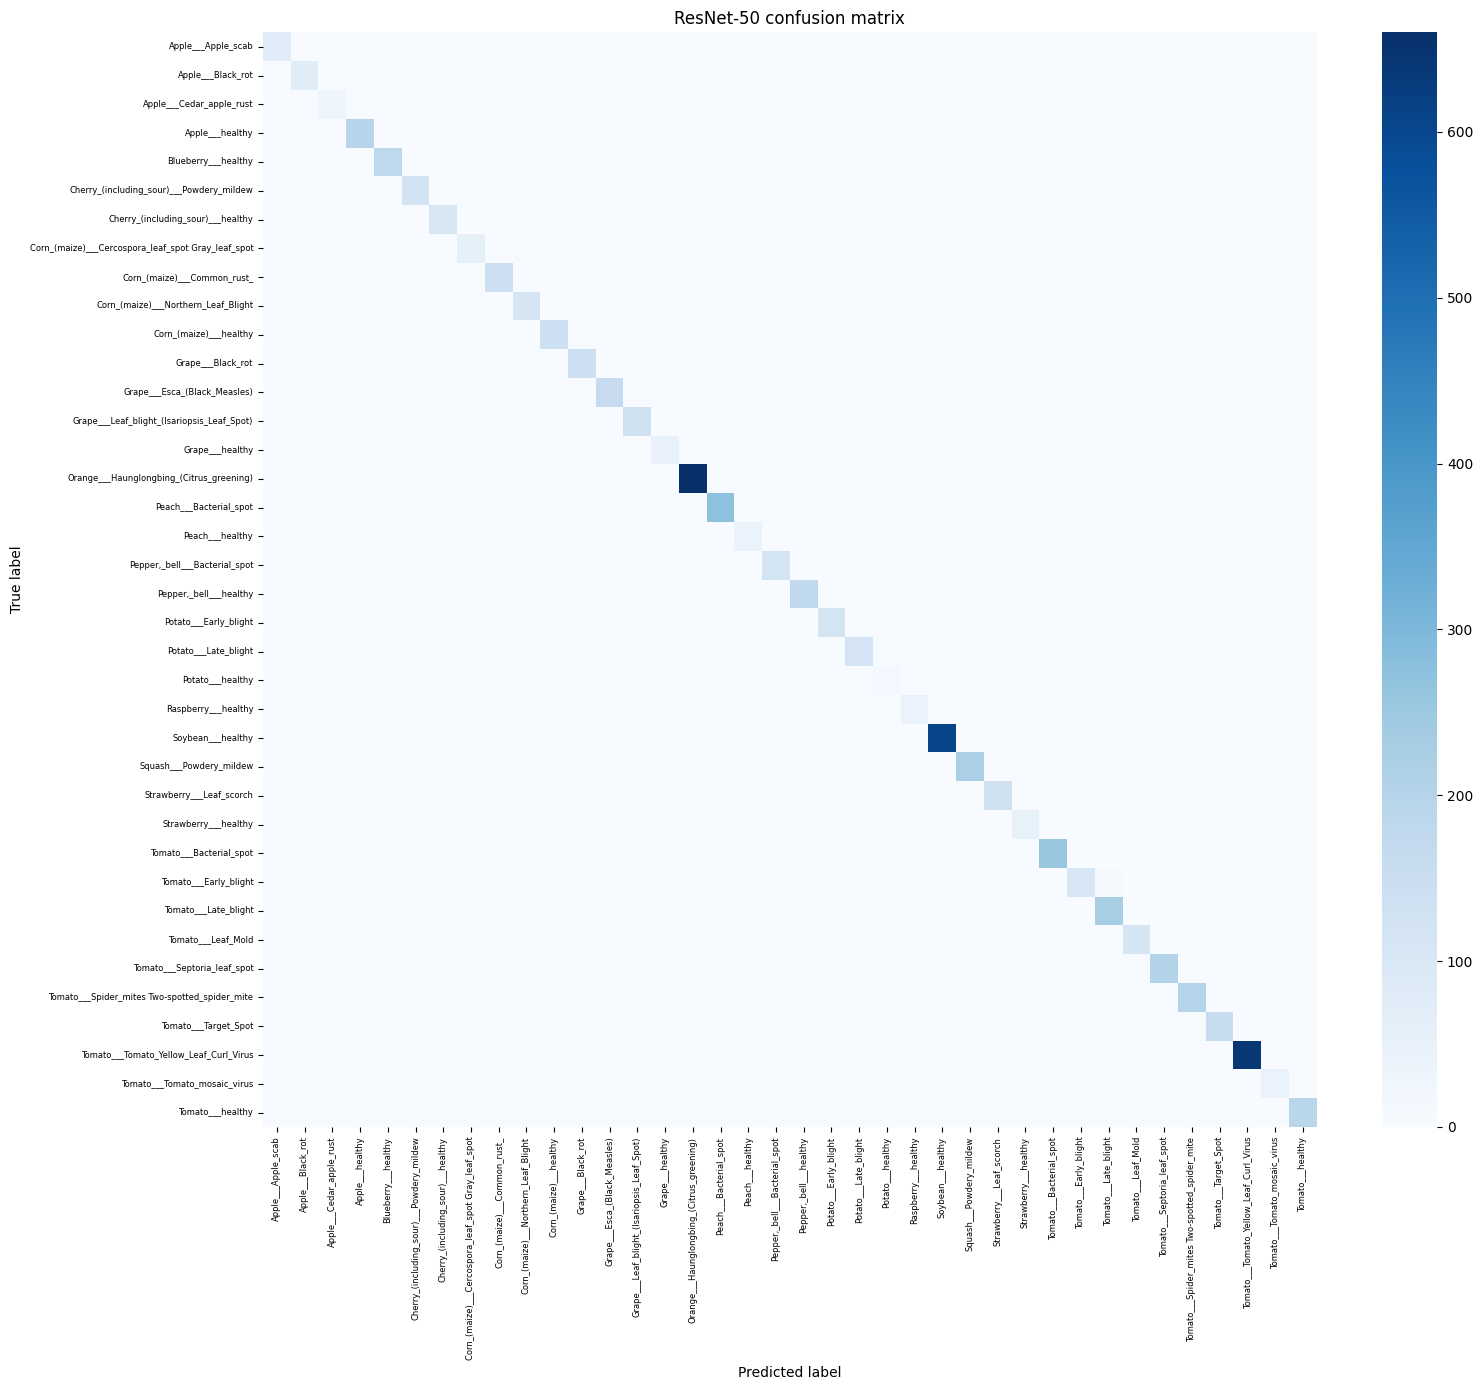

In [13]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(cm, cmap='Blues', ax=ax, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
ax.set(title='ResNet-50 confusion matrix', xlabel='Predicted label', ylabel='True label')
plt.xticks(rotation=90, fontsize=6)
plt.yticks(fontsize=6)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()

In [14]:
metrics = {
    'model':                    'ResNet-50',
    'test_accuracy':            float(test_acc),
    'test_f1_macro':            float(test_f1),
    'phase1_best_val_accuracy': float(max(history_p1['val_acc'])),
    'phase2_best_val_accuracy': float(max(history_p2['val_acc'])),
    'classes':                  CLASS_NAMES,
    'training_history':         {'phase1': history_p1, 'phase2': history_p2},
}
(RESULTS_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
print(json.dumps({k: v for k, v in metrics.items() if k != 'classes' and k != 'training_history'}, indent=2))

{
  "model": "ResNet-50",
  "test_accuracy": 0.9906369915579432,
  "test_f1_macro": 0.9834481974611312,
  "phase1_best_val_accuracy": 0.9757557158201626,
  "phase2_best_val_accuracy": 0.9921743133343564
}
